In [9]:
from pathlib import Path
print(Path.cwd())
print(Path(".").exists())

c:\Users\Dagi\Desktop\python_aau_training
True


In [3]:
import pandas as pd
file_dir_corrector='dci_session1/'
p = f"{file_dir_corrector}aau_dci_session1/s1_assets.csv"
assets = pd.read_csv(p)
print(assets.shape)

(360, 8)


In [5]:
print(assets.columns[:4].tolist())
print(assets["asset_id"].iloc[0])

['asset_id', 'zone', 'asset_type', 'install_year']
AA-0001


In [6]:
print(assets.dtypes["condition_score"])
print(assets.isna().sum().sum())

int64
0


In [8]:
import pandas as pd
df = pd.read_csv(path,sep="|")

NameError: name 'path' is not defined

In [10]:
p = f"{file_dir_corrector}aau_dci_session1/s1_assets_pipe.txt"
# Read file using pipe separator
pipes = pd.read_csv(p, 
sep="|")
# Inspect dataset structure
print(pipes.shape)
print(pipes.columns.tolist())

(360, 4)
['asset_id', 'zone', 'asset_type', 'condition_score']


In [11]:
p = f"{file_dir_corrector}aau_dci_session1/s1_assets_tabs.tsv"
# Read file using tab separator
tabs = pd.read_csv(p, 
sep="\t")
# Inspect dataset structure
print(tabs.shape)

(360, 3)


In [12]:
# Target text file path
p = f"{file_dir_corrector}aau_dci_session1/s1_assets_semicolon.txt"
# Read file using semicolon separator
semi = pd.read_csv(p, 
sep=";")
# Inspect dataset structure
print(semi.columns.tolist())

['asset_id', 'zone', 'install_year']


In [14]:
cols = ["asset_id", "zone", "status"]
# Read CSV with selected columns
small = pd.read_csv(f"{file_dir_corrector}aau_dci_session1/s1_assets.csv",
usecols=cols)
# Inspect result dimensions
print(small.shape)

(360, 3)


In [ ]:
p = f"{file_dir_corrector}aau_dci_session1/s1_assets.csv"
# Read preview with limited rows
sample = pd.read_csv(p, 
nrows=25)
# Inspect dimensions
print(sample.shape)
sample



(25, 8)


,asset_id,zone,asset_type,install_year,diameter_mm,condition_score,status,inspection_date
0,AA-0001,Gullele,Pump,1998,450,1,Operational,2026-06-26
1,AA-0002,Kirkos,Meter,2012,300,2,Operational,2026-06-03
2,AA-0003,Arada,Pump,2008,75,3,Inspection Due,2026-01-30
3,AA-0004,Bole,Pump,2019,300,3,Operational,2026-03-09
4,AA-0005,Lideta,Meter,1996,300,1,Operational,2026-09-06
5,AA-0006,Kirkos,Reservoir,2007,50,3,Operational,2026-06-11
6,AA-0007,Lideta,Pipe,1997,200,1,Inspection Due,2026-01-29
7,AA-0008,Bole,Pipe,2008,75,1,Operational,2026-09-03
8,AA-0009,Bole,Pipe,2004,450,3,Inspection Due,2026-03-26
9,AA-0010,Lideta,Pipe,2004,75,5,Inspection Due,2026-01-07


In [29]:
base = "https://raw.githubusercontent.com/yeab/deleteRep/refs/heads/main/s1_assets.csv"
url = ("yeab/deleteRep/blob/main/s1_assets.csv")
states = pd.read_csv(base)
print(states.columns.tolist())

['asset_id', 'zone', 'asset_type', 'install_year', 'diameter_mm', 'condition_score', 'status', 'inspection_date']


In [30]:
print(states.loc[0, "State"])
print(states.loc[0, "Postal"])
print(states.loc[0, "Population"])

KeyError: 'State'

In [33]:
from urllib.request import urlopen
url = ("https://raw.githubusercontent.com/"
"vega/vega-datasets/master/"
"data/seattle-weather.csv")
with urlopen(url, timeout=15) as response:
    print(response.readline().decode().strip())

date,precipitation,temp_max,temp_min,wind,weather


In [34]:
url = ("https://raw.githubusercontent.com/"
"vega/vega-datasets/master/"
"data/seattle-weather.csv")
weather = pd.read_csv(url, parse_dates=["date"])
print(weather.shape)

(1461, 6)


    year  population
65  1960    21376693
64  1961    21906102
63  1962    22465126
62  1963    23051637
61  1964    23666548
..   ...         ...
4   2021   122138588
3   2022   125384287
2   2023   128691692
1   2024   132059767
0   2025   135472051

[66 rows x 2 columns]
              year    population
count    66.000000  6.600000e+01
mean   1992.500000  6.181128e+07
std      19.196354  3.405191e+07
min    1960.000000  2.137669e+07
25%    1976.250000  3.269263e+07
50%    1992.500000  5.278132e+07
75%    2008.750000  8.739164e+07
max    2025.000000  1.354721e+08


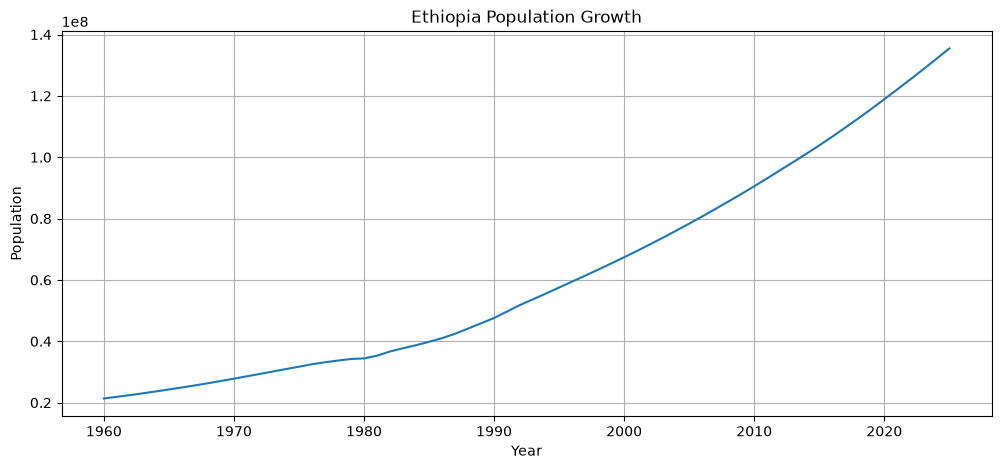

In [38]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

url = "https://api.worldbank.org/v2/country/ETH/indicator/SP.POP.TOTL?format=json&per_page=100"

response = requests.get(url)
response.raise_for_status()

data = response.json()[1]

df = pd.DataFrame([
    {
        "year": int(item["date"]),
        "population": item["value"]
    }
    for item in data if item["value"] is not None
])

df = df.sort_values("year")

print(df.head(200))
print(df.describe())

plt.figure(figsize=(12, 5))
plt.plot(df["year"], df["population"])
plt.title("Ethiopia Population Growth")
plt.xlabel("Year")
plt.ylabel("Population")
plt.grid()
plt.show()
